<a href="https://colab.research.google.com/github/juliaBerserk/rea-artificial-intelligence-systems-tasks/blob/main/Task4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import scipy
from io import IncrementalNewlineDecoder

In [2]:
#sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score

In [3]:
#глубокое обучение
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense

In [4]:
from matplotlib import pyplot
%matplotlib inline

In [7]:
# Загружаем необходимые данные. В датасете нет названия колонок.
# Целевой переменной является последний столбец
path='https://raw.githubusercontent.com/jbrownlee/Datasets/master/banknote_authentication.csv'
df=pd.read_csv(path, header=None)

In [6]:
df.head()

,0,1,2,3,4
0,3.62160,8.6661,-2.8073,-0.44699,0
1,4.54590,8.1674,-2.4586,-1.46210,0
2,3.86600,-2.6383,1.9242,0.10645,0
3,3.45660,9.5228,-4.0112,-3.59440,0
4,0.32924,-4.4552,4.5718,-0.98880,0


In [8]:
# Проведите описательную статистику для изучения данных
# с помощью метода describe()
df.describe()

,0,1,2,3,4
count,1372.000000,1372.000000,1372.000000,1372.000000,1372.000000
mean,0.433735,1.922353,1.397627,-1.191657,0.444606
std,2.842763,5.869047,4.310030,2.101013,0.497103
min,-7.042100,-13.773100,-5.286100,-8.548200,0.000000
25%,-1.773000,-1.708200,-1.574975,-2.413450,0.000000
50%,0.496180,2.319650,0.616630,-0.586650,0.000000
75%,2.821475,6.814625,3.179250,0.394810,1.000000
max,6.824800,12.951600,17.927400,2.449500,1.000000


In [9]:
# Проведите корреляцию признаков с помощью метода corr().
# Сделайте вывод.
df.corr()

,0,1,2,3,4
0,1.000000,0.264026,-0.380850,0.276817,-0.724843
1,0.264026,1.000000,-0.786895,-0.526321,-0.444688
2,-0.380850,-0.786895,1.000000,0.318841,0.155883
3,0.276817,-0.526321,0.318841,1.000000,-0.023424
4,-0.724843,-0.444688,0.155883,-0.023424,1.000000


In [10]:
# Проверьте с помощью метода info()
# типы данных и общую информацию.
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1372 entries, 0 to 1371
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   0       1372 non-null   float64
 1   1       1372 non-null   float64
 2   2       1372 non-null   float64
 3   3       1372 non-null   float64
 4   4       1372 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 53.7 KB


In [11]:
# Проверим данные в последней колонке. Сделаем вывод о балансировке данных
# и возможности создания нейронной сети:
df[4].value_counts()

,count
4,
0,762
1,610


In [15]:
# Создаем Х и у. Х приведем к типу данных float32
X, y = df.values[:, :-1], df.values[:, -1]
X=X.astype('float32')
X[1]

array([ 4.5459,  8.1674, -2.4586, -1.4621], dtype=float32)

In [16]:
# Применим LabelEncoder() для у
y=LabelEncoder().fit_transform(y)

In [17]:
# Разделим данные на обучающую и тестовую выборки.
# Параметр shuffle=True позволит перемешать выборку
X_train, X_test, y_train, y_test=train_test_split(X, y, test_size=0.25, shuffle=True)

In [24]:
# Создадим нейронную сеть
n_features=X.shape[1] # такие данные примет нейронная сеть на 1 слое
model=Sequential() # нейронная сеть последовательная
model.add(Dense(20, activation='relu', input_shape=(n_features,)))
model.add(Dense(10, activation='relu'))

In [25]:
# выходной слой
model.add(Dense(1, activation='sigmoid')) # 1- так как классов у нас 1 (либо 0 либо 1)

In [26]:
# Компилируем модель
model.compile(optimizer='adam', loss='binary_crossentropy')

In [27]:
# Проведем обучение модели. batch_size - часть данных,
# которую мы подаем на вход, verbose - визуализация
history=model.fit(X_train, y_train,
                  epochs=20,
                  batch_size=32,
                  verbose=1,
                  validation_data=(X_test,y_test))


Epoch 1/20
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.7061 - val_loss: 0.5378
Epoch 2/20
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.4626 - val_loss: 0.3768
Epoch 3/20
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.3423 - val_loss: 0.2761
Epoch 4/20
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.2644 - val_loss: 0.2149
Epoch 5/20
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.2083 - val_loss: 0.1675
Epoch 6/20
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.1638 - val_loss: 0.1327
Epoch 7/20
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.1298 - val_loss: 0.1061
Epoch 8/20
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.1033 - val_loss: 0.0851
Epoch 9/20
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0826 - val_loss: 0.0682
Epoch 10/20
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0662 - val_loss: 0.0559
Epoch 11/20
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0530 - val_loss: 0.0454
Epoch 12/20
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0427 - val_lo

In [28]:
# Получим прогноз для X_test
yhat = model.predict(X_test)  # X_test - ваши входные данные
predicted_classes = np.argmax(yhat, axis=-1)

11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step


In [29]:
# Валидируем наш прогноз
score=accuracy_score(y_test, predicted_classes)
print('Accuracy:', score)

Accuracy: 0.5860058309037901


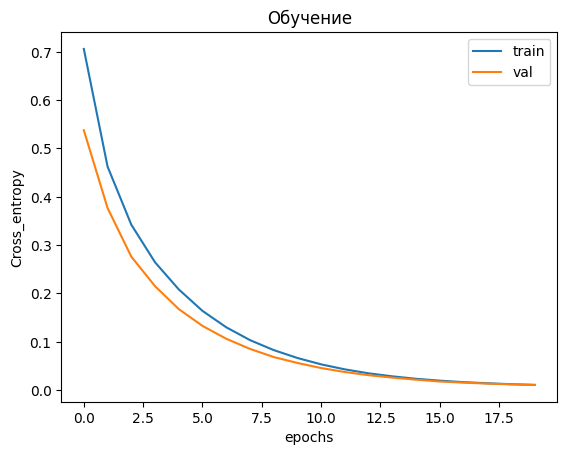

In [30]:
# Осуществим визуализацию процесса обучения
pyplot.title('Обучение')
pyplot.xlabel('еpochs')
pyplot.ylabel('Cross_entropy')
pyplot.plot(history.history['loss'], label='train')
pyplot.plot(history.history['val_loss'], label='val')
pyplot.legend()
pyplot.show()

In [31]:
# Применим кросс-валидацию для обучения созданной нейронной сети:
from sklearn.model_selection import StratifiedKFold
kfold=StratifiedKFold(10)
scores=[] #пустой список для метрик

for train_ix, test_ix in kfold.split(X,y):
  X_train, X_test, y_train, y_test = X[train_ix], X[test_ix], y[train_ix], y[test_ix]
  n_features=X.shape[1] #размерность

In [33]:
model=Sequential() # нейронная сеть последовательная
model.add(Dense(20, activation='relu', input_shape=(n_features,)))
model.add(Dense(10, activation='relu'))

In [34]:
# выходной слой
model.add(Dense(1, activation='sigmoid')) # 1- так как классов у нас 1 (либо 0 либо 1)

In [36]:
#Компилируем модель
model.compile(optimizer='adam', loss='binary_crossentropy')

In [37]:
#Обучение модели
history=model.fit(X_train, y_train,
                  epochs=20,
                  batch_size=32,
                  verbose=1,
                  validation_data=(X_test,y_test))

Epoch 1/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 3s 22ms/step - loss: 0.7164 - val_loss: 0.6001
Epoch 2/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.5434 - val_loss: 0.4982
Epoch 3/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.4400 - val_loss: 0.3942
Epoch 4/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.3081 - val_loss: 0.2512
Epoch 5/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.1883 - val_loss: 0.1606
Epoch 6/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.1184 - val_loss: 0.1083
Epoch 7/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0788 - val_loss: 0.0777
Epoch 8/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0554 - val_loss: 0.0575
Epoch 9/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0412 - val_loss: 0.0461
Epoch 10/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0316 - val_loss: 0.0365
Epoch 11/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0246 - val_loss: 0.0304
Epoch 12/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0200 - va

In [38]:
#predict test_set
yhat = model.predict(X_test)  # X_test - ваши входные данные
predicted_classes = np.argmax(yhat, axis=-1)

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step


In [39]:
#Валидируем наш прогноз
score=accuracy_score(y_test, predicted_classes)
print('Accuracy:', score)

Accuracy: 0.5547445255474452


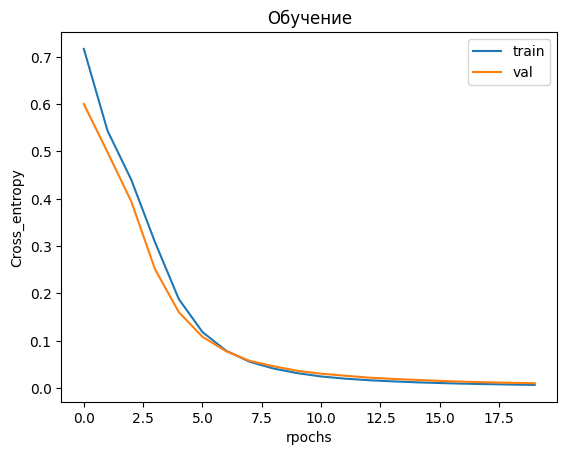

Средняя точность при кроссвалидации: 0.5547445255474452


In [43]:
#визуализация процесса обучения
pyplot.title('Обучение')
pyplot.xlabel('rpochs')
pyplot.ylabel('Cross_entropy')
pyplot.plot(history.history['loss'], label='train')
pyplot.plot(history.history['val_loss'], label='val')
pyplot.legend()
pyplot.show()

scores.append(score)
print('Средняя точность при кроссвалидации:', (np.mean(scores)))

Epoch 1/20


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


39/39 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 0.9174 - val_loss: 0.7516
Epoch 2/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.6957 - val_loss: 0.5813
Epoch 3/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.5099 - val_loss: 0.4306
Epoch 4/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.3479 - val_loss: 0.2820
Epoch 5/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.2017 - val_loss: 0.1707
Epoch 6/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.1212 - val_loss: 0.1181
Epoch 7/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0819 - val_loss: 0.0866
Epoch 8/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0596 - val_loss: 0.0667
Epoch 9/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0460 - val_loss: 0.0581
Epoch 10/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0359 - val_loss: 0.0445
Epoch 11/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0287 - val_loss: 0.0391
Epoch 12/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0237 - val_loss: 0.0325

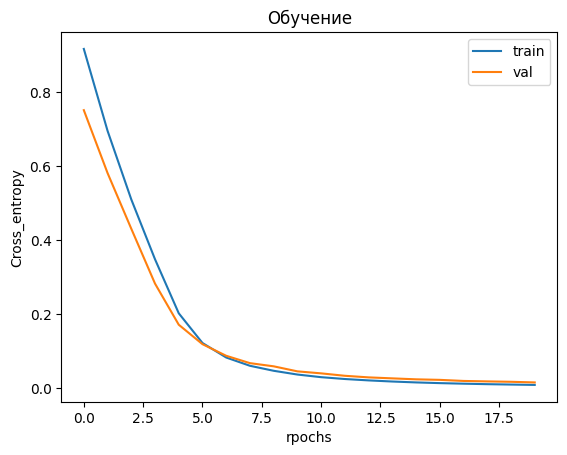

Средняя точность при кроссвалидации: 0.5547445255474452


In [45]:
# Применим кросс-валидацию для обучения созданной нейронной сети:
from sklearn.model_selection import StratifiedKFold
kfold=StratifiedKFold(10)
scores=[] #пустой список для метрик

for train_ix, test_ix in kfold.split(X,y):
  X_train, X_test, y_train, y_test = X[train_ix], X[test_ix], y[train_ix], y[test_ix]
  n_features=X.shape[1] #размерность
model=Sequential() # нейронная сеть последовательная
model.add(Dense(20, activation='relu', input_shape=(n_features,)))
model.add(Dense(10, activation='relu'))
# выходной слой
model.add(Dense(1, activation='sigmoid')) # 1- так как классов у нас 1 (либо 0 либо 1)
#Компилируем модель
model.compile(optimizer='adam', loss='binary_crossentropy')
#Обучение модели
history=model.fit(X_train, y_train,
                  epochs=20,
                  batch_size=32,
                  verbose=1,
                  validation_data=(X_test,y_test))
#predict test_set
yhat = model.predict(X_test)  # X_test - ваши входные данные
predicted_classes = np.argmax(yhat, axis=-1)
#Валидируем наш прогноз
score=accuracy_score(y_test, predicted_classes)
print('Accuracy:', score)
#визуализация процесса обучения
pyplot.title('Обучение')
pyplot.xlabel('rpochs')
pyplot.ylabel('Cross_entropy')
pyplot.plot(history.history['loss'], label='train')
pyplot.plot(history.history['val_loss'], label='val')
pyplot.legend()
pyplot.show()

scores.append(score)
print('Средняя точность при кроссвалидации:', (np.mean(scores)))